# Order and density shape locust directional alignment in virtual reality

Juvenile desert locusts (*Schistocerca gregaria*) align their heading with the
direction of neighbor motion, a core ingredient of marching behavior. In the virtual-reality experiments of S. Sayin et al., "The behavioral mechanisms governing collective motion in swarming locusts," *Science* **387**(6737), 995-1000 (2025); [doi:10.1126/science.adq7832](https://doi.org/10.1126/science.adq7832), focal locusts walked on a
motion-compensating spherical treadmill surrounded by a panoramic projection
of moving **virtual conspecifics**. The virtual swarm was defined by two
continuous stimulus parameters:

- **order** — the coherence of the virtual motion, 0 = disordered to 1 =
  perfectly aligned (six levels: 0, 0.2, 0.4, 0.6, 0.8, 1.0);
- **density** — the number of virtual locusts per m$^2$ (six levels: 1, 4, 8,
  16, 32, 64).

The biological question: is the focal locust's directional alignment driven
primarily by the directional structure of neighbor motion (order), or does the
number of neighbors (density) matter comparably?


This notebook repeats the individual-level fixed-effect screening and PSIS-LOO sweep, then fits the final step-level hierarchical von Mises model with `brms` and the `unwrap_von_mises` family. The final model has a population mean-direction regression and a concentration random intercept per animal.

The alignment estimand is
$\mathcal{A}(\mathbf{x})=R(\kappa(\mathbf{x}))\cos(\mu(\mathbf{x}))$,
where $R(\kappa)=I_1(\kappa)/I_0(\kappa)$ and $0$ is the virtual march
direction. Density and order vary **between** animals; no animal
experiences multiple stimulus conditions. The raw tracking parts require
approximately 870 MB on first download, followed by rediscretization.


## Setup

Follow the [R setup](../getting-started-r.md) page once, select the
**R (`ir`)** kernel, and run all cells in order. The setup cell checks
that the pinned packages and CmdStan are available; it stops with a
pointer to the setup page if the one-time setup has not been run.
Running the notebook records versions, diagnostics, inline PNGs, and
vector PDFs.


In [1]:
# Setup: check that this notebook's stack is available. The examples
# are verified against the pinned package set recorded in renv.lock, so
# this cell deliberately does not auto-install: an unpinned install
# could silently drift from the verified set. Run the one-time setup on
# the R setup page first (docs/getting-started-r.md).

required <- c("brms", "posterior", "loo", "circular", "ggplot2", "ragg", "arrow")
missing <- required[!vapply(required, requireNamespace, logical(1),
  quietly = TRUE)]
if (length(missing))
  stop("Missing R package(s): ", paste(missing, collapse = ", "),
       " - run the one-time setup on the R setup page first:",
       "\n  https://jgraving.github.io/unwrap/getting-started-r/")

cmdstan_ok <- tryCatch(
  dir.exists(as.character(cmdstanr::cmdstan_path())),
  error = function(e) FALSE)
if (!cmdstan_ok)
  stop("cmdstanr/CmdStan is not available - run the one-time setup on the",
       " R setup page first:",
       "\n  https://jgraving.github.io/unwrap/getting-started-r/")

In [2]:
suppressPackageStartupMessages({
    library(brms)
    library(posterior)
    library(loo)
    library(circular)
    library(ggplot2)
    library(arrow)
})

# The repository's R helpers (custom brms family + circular statistics)
# live next to the notebook; make them reachable regardless of the
# kernel's working directory.
repo_root <- if (file.exists(file.path("..", "R", "unwrap_family.R"))) ".." else
    if (file.exists(file.path("R", "unwrap_family.R"))) "." else
    stop("Run this notebook from notebooks_r/ or from the repository root.")
source(file.path(repo_root, "R", "unwrap_family.R"))
source(file.path(repo_root, "R", "unwrap_functions.R"))

# The figure code writes to the repository-relative figures directory.
FIG_DIR <- file.path(repo_root, "figures", "locust_density_order")
dir.create(FIG_DIR, recursive = TRUE, showWarnings = FALSE)
theme_set(theme_minimal(base_size = 12))

# Without X11/cairo (most server R installs) the default device cannot
# rasterise, so each figure renders to a PNG through ragg and displays
# inline; a vector PDF is saved alongside as the portable copy.
show_figure <- function(plot, name, width, height, res = 110) {
  file <- file.path(FIG_DIR, paste0(name, ".png"))
  ragg::agg_png(file, width = width, height = height, units = "in",
                res = res)
  print(plot)
  invisible(dev.off())
  IRdisplay::display_png(file = file)
  invisible(NULL)
}


SEED <- 123
set.seed(SEED)
quick_run <- Sys.getenv("UNWRAP_R_QUICK") == "1"
CHAINS <- 4L
# Hierarchical models need longer adaptation and more retained draws than
# the introductory GLM. Quick mode keeps the full data and model and shortens
# the Monte Carlo plotting/bootstrapping budgets and the screening fits below.
# The final fit keeps its full sampling budget even in quick mode: its
# R-hat/ESS gate needs the ESS the full budget provides (the same convention
# as the mixture notebook).
ITER <- 3000L
WARMUP <- 2000L
ADAPT_DELTA <- 0.97
# The tighter adapt_delta protects the grouped concentration geometry;
# these are execution budgets, not a claim of verified convergence.

c(R = as.character(getRversion()),
  brms = as.character(packageVersion("brms")),
  cmdstanr = as.character(packageVersion("cmdstanr")),
  posterior = as.character(packageVersion("posterior")),
  loo = as.character(packageVersion("loo")),
  circular = as.character(packageVersion("circular")),
  ggplot2 = as.character(packageVersion("ggplot2")),
  ragg = as.character(packageVersion("ragg")),
  arrow = as.character(packageVersion("arrow")))


Loading required package: cmdstanr



This is cmdstanr version 0.9.0



- CmdStanR documentation and vignettes: mc-stan.org/cmdstanr



- CmdStan path: /home/jake/.cmdstan/cmdstan-2.40.0



- CmdStan version: 2.40.0



R          brms      cmdstanr     posterior           loo 
      "4.5.3"      "2.23.0"       "0.9.0"       "1.7.1" "2.10.1.9000" 
     circular       ggplot2          ragg         arrow 
      "0.5.2"       "4.0.3"       "1.5.2"      "26.0.0"

## Figure style

Figures render inline and save vector PDFs under
`figures/locust_density_order/`. The condition colors match those of the
Python analysis. All angular calculations use radians and circular summaries.


In [3]:
circ_mean <- function(a) atan2(mean(sin(a)), mean(cos(a)))
resultant <- function(a) Mod(mean(exp(1i * a)))
circ_sd <- function(a, m = circ_mean(a)) {
  sqrt(-2 * log(min(1, Mod(mean(exp(1i * (a - m)))))))
}
# Scaled Bessel functions avoid overflow when concentrations are large.
A1_safe <- function(k) {
  out <- besselI(k, 1, expon.scaled = TRUE) /
    besselI(k, 0, expon.scaled = TRUE)
  if (is.matrix(k)) dim(out) <- dim(k)
  out
}
vm_logpdf <- function(y, mu, kappa) {
  kappa * (cos(y - mu) - 1) - log(2 * pi) -
    log(besselI(kappa, 0, expon.scaled = TRUE))
}
hdi <- function(x, prob = 0.95) {
  x <- sort(as.numeric(x))
  stopifnot(length(x) > 1L, all(is.finite(x)))
  gap <- min(length(x) - 1L, floor(prob * length(x)))
  starts <- seq_len(length(x) - gap)
  j <- starts[which.min(x[starts + gap] - x[starts])]
  c(low = x[j], high = x[j + gap])
}
interval_row <- function(x, angular = FALSE, prob = 0.95) {
  m <- if (angular) circ_mean(x) else mean(x)
  # Unwrap angular intervals around their circular mean before drawing;
  # display endpoints can lie just beyond +/-pi to avoid a false long arc.
  z <- if (angular) m + mod_circular(x - m) else x
  c(mean = m, hdi(z, prob))
}
inverse_A1 <- function(r) {
  if (r <= 0) {
    return(0)
  }
  if (r >= 1) {
    return(Inf)
  }
  upper <- max(2, 1 / (1 - r))
  uniroot(function(k) A1_safe(k) - r, c(0, upper), tol = 1e-9)$root
}
# Exact tutorial sampler convention: scalar mu/kappa, then wrap the draw.
vmu <- function(m) circular::circular(
    m, units = "radians", template = "none", modulo = "2pi")
vm_ctrl <- list(units = "radians", template = "none", modulo = "2pi")
simulate_angles <- function(mu, kappa) {
  stopifnot(is.matrix(mu), identical(dim(mu), dim(kappa)))
  replicated <- matrix(0, nrow = nrow(mu), ncol = ncol(mu))
  for (d in seq_len(nrow(mu))) {
    for (i in seq_len(ncol(mu))) {
      replicated[d, i] <- as.numeric(circular::rvonmises(1,
        mu = vmu(mu[d, i]), kappa = kappa[d, i],
        control.circular = vm_ctrl))
    }
  }
  mod_circular(replicated)
}
save_figure <- function(plot, name, width = 8, height = 4) {
  ggsave(file.path(FIG_DIR, paste0(name, ".pdf")), plot,
         width = width, height = height)
  show_figure(plot, name, width, height)
}

# Same published source files as the Python loaders; keep their local
# checkout under the repository root, reachable from notebooks_r/ too.
# An existing checkout can be supplied through UNWRAP_DATA_ROOT.
data_root <- Sys.getenv("UNWRAP_DATA_ROOT",
                        unset = file.path(repo_root, "unwrap-data"))
ensure_data <- function(subdir) {
  target <- file.path(data_root, subdir)
  if (!dir.exists(target)) {
    if (!dir.exists(data_root)) {
      status <- system2("git", c("clone", "--depth", "1",
        "--filter=blob:none", "--sparse",
        "https://github.com/jgraving/unwrap-data.git", shQuote(data_root)))
      if (status != 0L) stop("Could not fetch the published study data.")
    }
    # Sparse checkout downloads only this study; later notebooks may add
    # their own subdirectory to the same checkout without replacing it.
    status <- system2("git", c("-C", shQuote(data_root),
                              "sparse-checkout", "add", subdir))
    if (status != 0L) stop("Could not materialize the study subdirectory.")
  }
  stopifnot(dir.exists(target))
  target
}


## 1. Load and rediscretize the trajectories

Read every `density_order/XY_part_*.parquet` part in lexical filename order, retaining the raw `fname`, `order`, `density`, `X`, and `Y` columns. The files are storage parts rather than animals, so they are joined before trajectories are split. The raw set contains 470 animals; processing retains 440 animals and 18,641 steps.

Each raw trajectory is densely interpolated at tolerance 0.0001, then resampled at equal arc length: starting at the first position, each successive step lands at the remaining dense point nearest a Euclidean distance of six body lengths ($6\times0.04=0.24$ m), discarding the intervening dense points. The nearest-distance search (rather than cumulative-arc-length interpolation) is deliberate: on looping paths it reproduces the published step table. Drop missing positions and trajectories yielding fewer than two points.


In [4]:
data_dir <- ensure_data("density_order")
files <- sort(list.files(data_dir, pattern = "^XY_part_.*[.]parquet$", full.names = TRUE))
stopifnot(length(files) > 0L)
parts <- lapply(files, function(f) {
  tryCatch(as.data.frame(arrow::read_parquet(f,
    col_select = c("X", "Y", "fname", "order", "density"))),
    error = function(e) {
      # Python's loader skips corrupted/partial Parquet parts too.
      cat("Skipped unreadable part:", basename(f), conditionMessage(e), "\n")
      NULL
    })
})
parts <- Filter(Negate(is.null), parts)
stopifnot(length(parts) > 0L)
raw <- do.call(rbind, parts)
rm(parts)
invisible(gc())
raw$fname <- as.character(raw$fname)
cat("Raw animals:", length(unique(raw$fname)), "\n")
sort(unique(raw$density))
sort(unique(raw$order))


Raw animals: 470 


[1]  1  4  8 16 32 64

[1] 0.0 0.2 0.4 0.6 0.8 1.0

In [5]:
rediscretize_trajectory <- function(x, y, step_length = 6 * 0.04, tolerance = 0.0001) {
  counts <- pmax(as.integer(sqrt(diff(x)^2 + diff(y)^2) / tolerance), 2L)
  n_dense <- sum(counts) - length(counts) + 1L
  dense_x <- dense_y <- numeric(n_dense)
  cursor <- 1L
  for (i in seq_along(counts)) {
    sx <- seq(x[i], x[i + 1L], length.out = counts[i])
    sy <- seq(y[i], y[i + 1L], length.out = counts[i])
    if (i > 1L) {
      sx <- sx[-1L]
      sy <- sy[-1L]
    }
    take <- cursor + seq_along(sx) - 1L
    dense_x[take] <- sx
    dense_y[take] <- sy
    cursor <- cursor + length(sx)
  }
  new_x <- x[1]
  new_y <- y[1]
  while (length(dense_x) > 0L) {
    distances <- sqrt((dense_x - tail(new_x, 1))^2 +
                       (dense_y - tail(new_y, 1))^2)
    j <- which.min(abs(distances - step_length))
    if (distances[j] < step_length - tolerance) break
    new_x <- c(new_x, dense_x[j])
    new_y <- c(new_y, dense_y[j])
    keep <- seq.int(j, length(dense_x))
    dense_x <- dense_x[keep]
    dense_y <- dense_y[keep]
    if (j == 1L) break
  }
  data.frame(X = new_x, Y = new_y)
}
raw_ids <- unique(raw$fname)
rows_by_animal <- split(seq_len(nrow(raw)), factor(raw$fname, levels = raw_ids))
step_tables <- lapply(seq_along(raw_ids), function(i) {
  g <- raw[rows_by_animal[[i]], ]
  g <- g[complete.cases(g[c("X", "Y")]), ]
  if (nrow(g) < 2L) return(NULL)
  stopifnot(length(unique(g$order)) == 1L, length(unique(g$density)) == 1L)
  path <- rediscretize_trajectory(g$X, g$Y)
  if (nrow(path) < 2L) return(NULL)
  dx <- diff(path$X)
  dy <- diff(path$Y)
  data.frame(fname = raw_ids[i], order = g$order[1], density = g$density[1],
    X = path$X[-1], Y = path$Y[-1], dX = dx, dY = dy,
    direction = atan2(dy, dx))
})
merged_df <- do.call(rbind, Filter(Negate(is.null), step_tables))
merged_df$animal_id <- factor(match(merged_df$fname, unique(merged_df$fname)) - 1L)
rm(raw, rows_by_animal, step_tables)
invisible(gc())
cat("Modeling animals:", nlevels(merged_df$animal_id),
    " Steps:", nrow(merged_df), "\n")
# EQUIVALENCE NOTE: compare these counts and per-animal headings against
# Python's 440 animals / 18,641 steps when baking. The R port intentionally
# reproduces the dense-point nearest-distance algorithm, not an alternative
# geometric approximation. Floating-point ties need local comparison.
stopifnot(nlevels(merged_df$animal_id) == 440L, nrow(merged_df) == 18641L)


Modeling animals: 440  Steps: 18641 


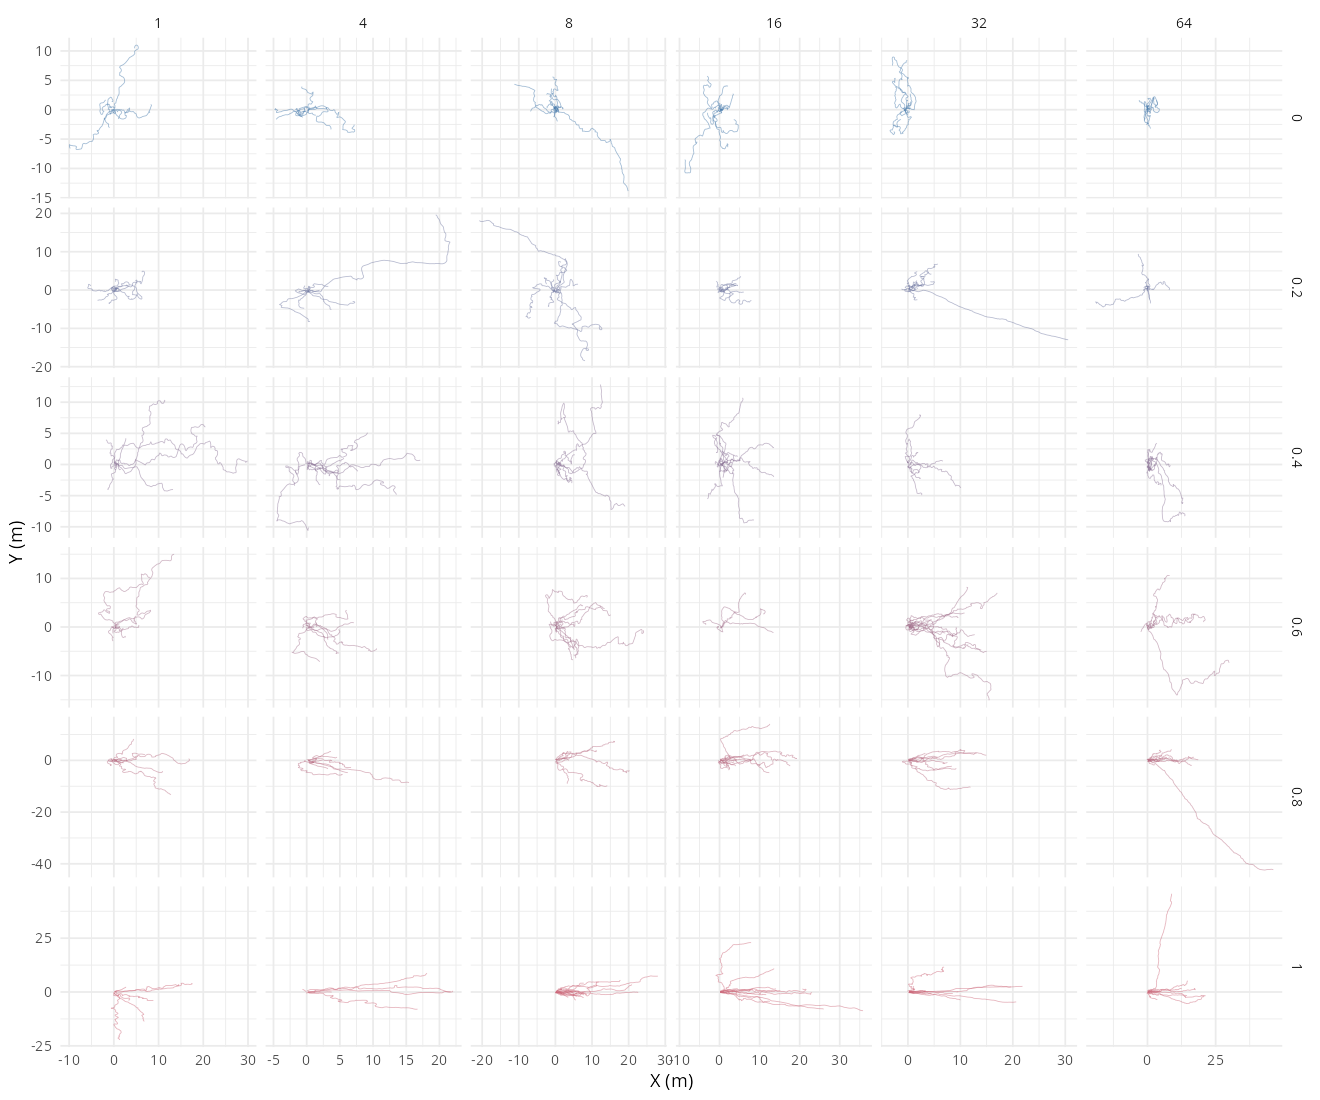

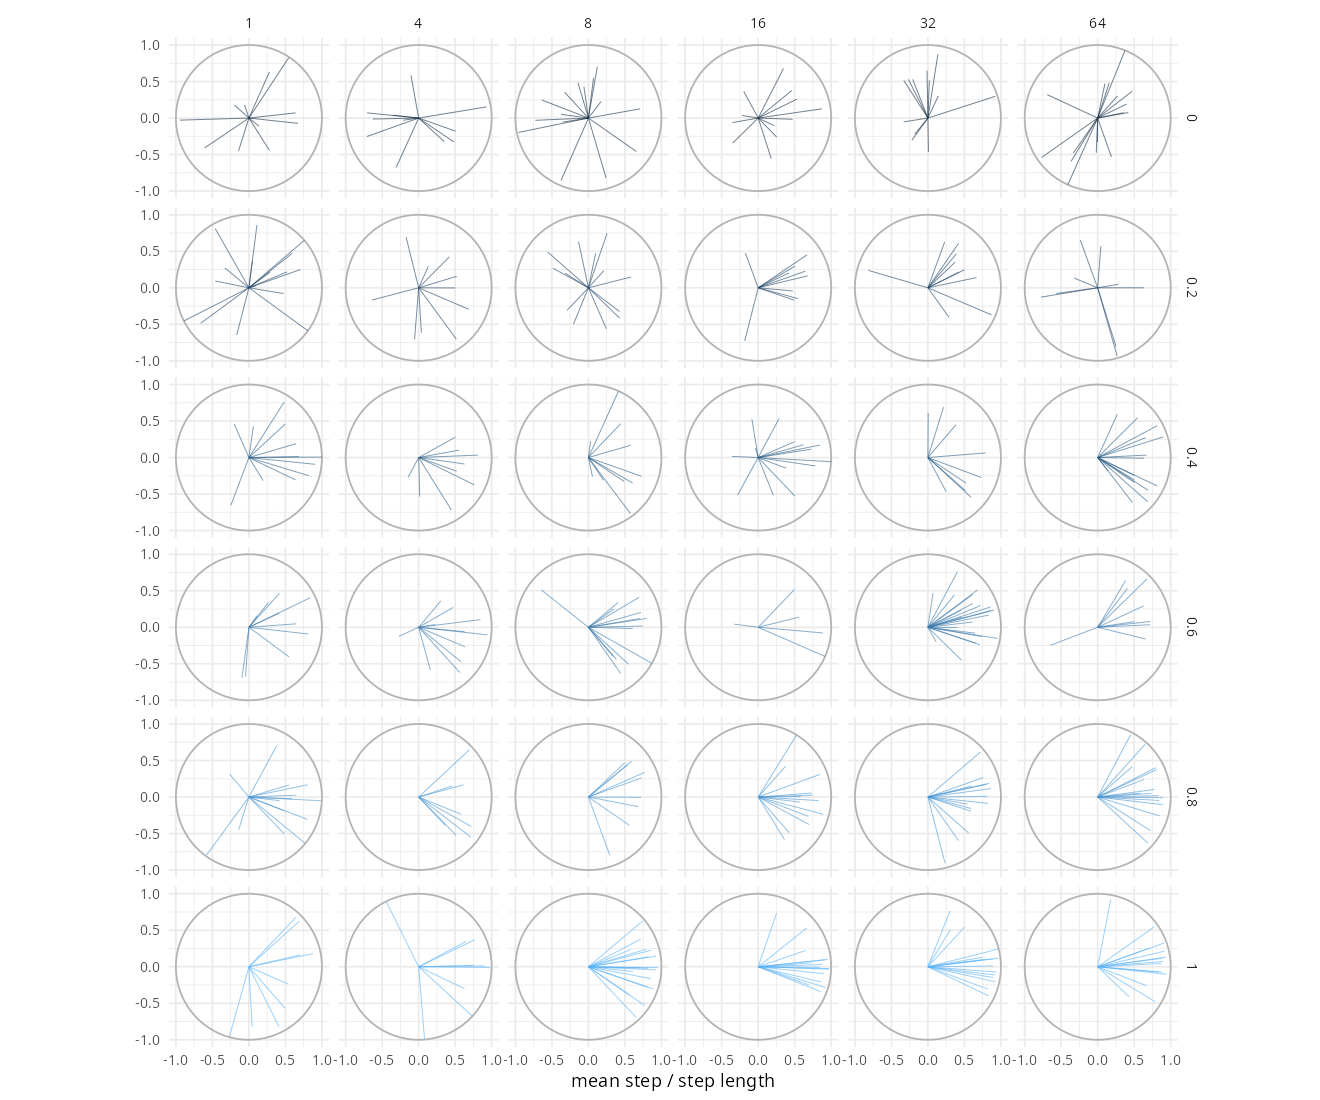

In [6]:
# Observed trajectories, one panel per experimental cell.
p_paths <- ggplot(merged_df, aes(X, Y, group = animal_id, colour = order)) +
  geom_path(alpha = 0.5, linewidth = 0.25) +
  facet_grid(order ~ density, scales = "free") +
  scale_colour_gradient(low = "#4477AA", high = "#CC6677") +
  labs(x = "X (m)", y = "Y (m)") + theme(legend.position = "none")
save_figure(p_paths, "trajectories_order_by_density_grid", 12, 10)
vectors <- aggregate(cbind(dX, dY) ~ order + density + fname,
                     data = merged_df, FUN = mean)
vectors$vx <- vectors$dX / (6 * 0.04)
vectors$vy <- vectors$dY / (6 * 0.04)
circle <- data.frame(x = cos(seq(-pi, pi, length.out = 201)),
                     y = sin(seq(-pi, pi, length.out = 201)))
p_vectors <- ggplot(vectors) +
  geom_path(data = circle, aes(x, y), inherit.aes = FALSE, colour = "grey70") +
  geom_segment(aes(x = 0, y = 0, xend = vx, yend = vy, colour = order),
                alpha = 0.6, linewidth = 0.3) +
  facet_grid(order ~ density) + coord_equal() +
  labs(x = "mean step / step length", y = "") + theme(legend.position = "none")
save_figure(p_vectors, "mean_vectors_order_by_density_grid", 12, 10)


The synthetic schematic separates the two stimulus dimensions: density
controls the number of virtual neighbors; order controls coherence of
their headings. The schematic is illustrative and never enters a fit.


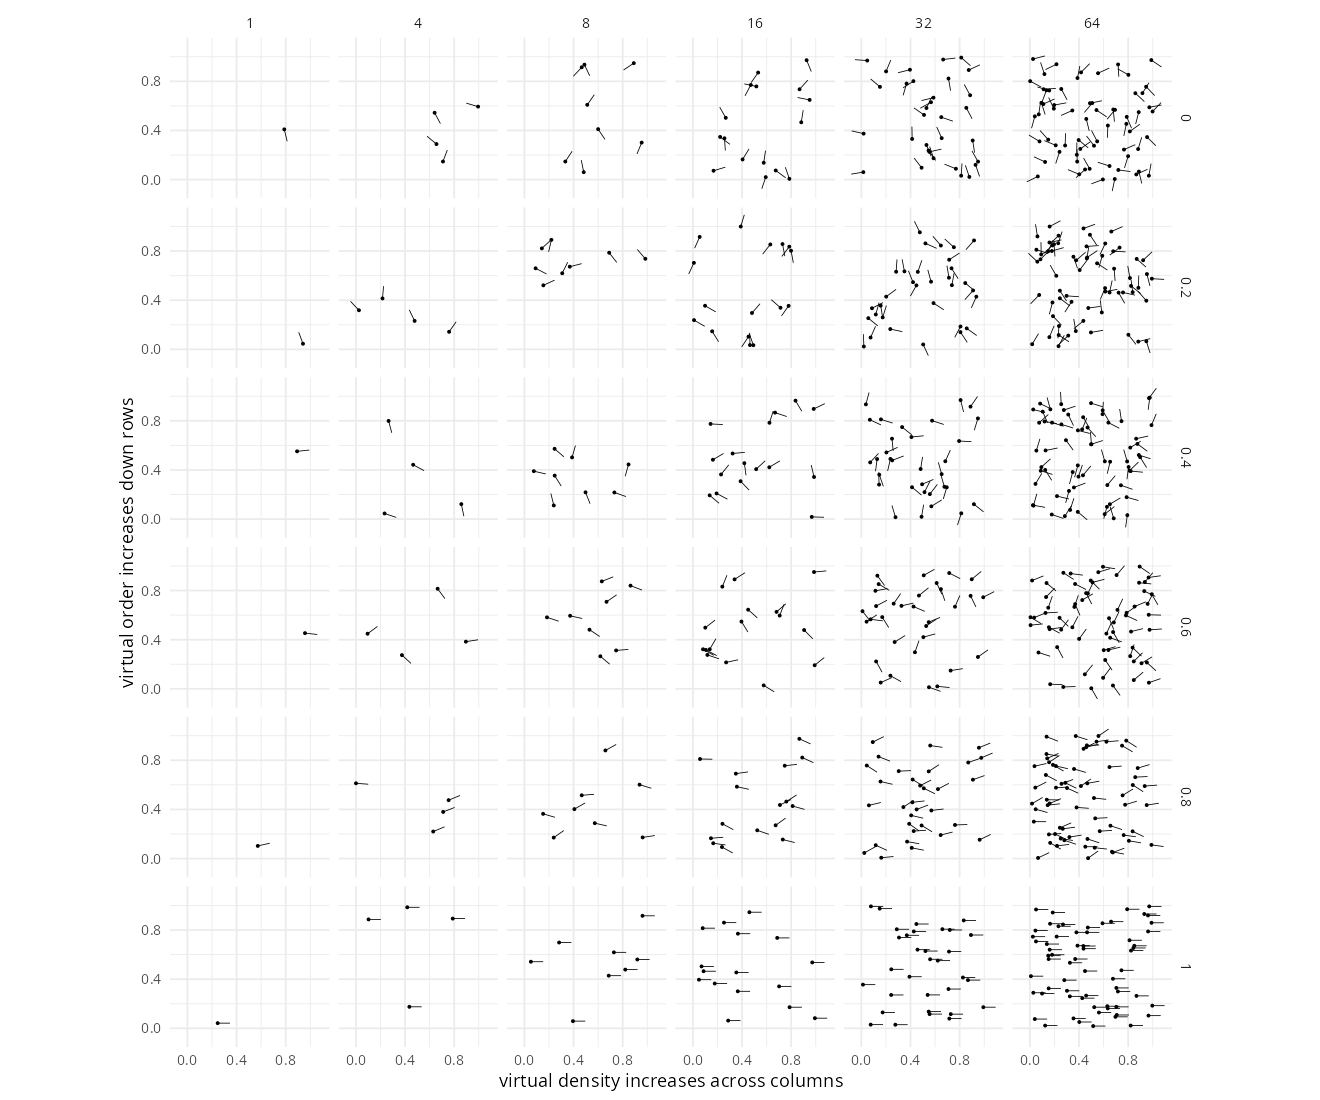

In [7]:
set.seed(SEED)
density_levels <- c(1, 4, 8, 16, 32, 64)
order_levels <- seq(0, 1, by = 0.2)
stimulus_grid <- expand.grid(order = order_levels, density = density_levels)
schematic <- do.call(rbind, lapply(seq_len(nrow(stimulus_grid)), function(i) {
  n <- stimulus_grid$density[i]
  o <- stimulus_grid$order[i]
  theta <- runif(n, -pi, pi) * (1 - o)
  x <- runif(n)
  y <- runif(n)
  data.frame(order = o, density = n, x = x, y = y,
             xend = x + 0.1 * cos(theta), yend = y + 0.1 * sin(theta))
}))
p_stimulus <- ggplot(schematic, aes(x, y)) + geom_point(size = 0.5) +
  geom_segment(aes(xend = xend, yend = yend), linewidth = 0.25) +
  facet_grid(order ~ density) + coord_equal() +
  labs(x = "virtual density increases across columns", y = "virtual order increases down rows")
save_figure(p_stimulus, "order_density_pairwise_trajectories_only", 12, 10)


## 2. Build the individual screening table

Average each animal's displacement vectors, then take their angle:
$y=\operatorname{atan2}(\overline{dY},\overline{dX})$. This is one
observation per animal. Order is scaled as `2 * order - 1` and density
as `2 * log2(density) / log2(64) - 1`. The initial interaction fit is
uncentered; the five-model sweep that follows uses default predictor
centering.


In [8]:
screen_df <- vectors[order(vectors$order, vectors$density, vectors$fname), ]
screen_df$y <- mod_circular(atan2(screen_df$dY, screen_df$dX))
screen_df$t_order <- 2 * screen_df$order - 1
screen_df$t_density <- 2 * log2(screen_df$density) / log2(64) - 1
stopifnot(nrow(screen_df) == 440L,
          all(abs(screen_df$t_order) <= 1), all(abs(screen_df$t_density) <= 1))
head(screen_df)


,order,density,fname,dX,dY,vx,vy,y,t_order,t_density
,<dbl>,<int>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
25,0,1,20220831_1031,-0.22705194,-0.006859515,-0.94604974,-0.02858131,-3.1113906,-1,-1
36,0,1,20220831_1631,-0.01440162,0.043187751,-0.06000676,0.17994896,1.8926658,-1,-1
49,0,1,20220902_1816,0.03309344,-0.026387840,0.13788935,-0.10994933,-0.6731374,-1,-1
92,0,1,20220907_1101,0.15344417,0.016937418,0.63935072,0.07057258,0.1099366,-1,-1
139,0,1,20220910_1300,-0.14585667,-0.098389933,-0.60773613,-0.40995805,-2.5481413,-1,-1
143,0,1,20220910_1524,0.06737033,0.151460286,0.28070973,0.63108452,1.1522707,-1,-1


In [9]:
diagnose_fit <- function(fit, circular_parameters = character()) {
  # NUTS divergences. Not every brms/cmdstanr combination keeps the
  # per-iteration divergence flag in the fit object, so probe for it and
  # report what the fit object actually carries (the R-hat and ESS values
  # below are the primary convergence checks either way).
  divergences <- tryCatch({
    div_flags <- lapply(fit$fit@sim$samples, function(ch) ch[["divergent"]])
    if (any(vapply(div_flags, is.null, logical(1)))) NA_real_
    else sum(unlist(div_flags))
  }, error = function(e) NA_real_)
  if (is.na(divergences)) {
      cat("Divergences: not retained in this fit object (see R-hat/ESS below).\n")
  } else {
      cat("Divergences:", divergences, "\n")
  }
  available <- posterior::variables(posterior::as_draws_array(fit))
  parameters <- available[grepl("^(b_|sd_|r_|kmu_)", available)]
  draws_array <- posterior::subset_draws(posterior::as_draws_array(fit),
                                         variable = parameters)
  out <- do.call(rbind, lapply(parameters, function(p) {
    # Preserve iteration x chain shape: flattening loses between-chain
    # information and would make the R-hat/ESS checks misleading.
    x <- as.matrix(draws_array[, , p])
    angular <- p %in% circular_parameters
    z <- if (angular) mod_circular(x - circ_mean(x)) else x
    stopifnot(all(is.finite(x)))
    data.frame(parameter = p,
      mean = if (angular) circ_mean(x) else mean(x),
      sd = if (angular) circ_sd(x) else sd(as.numeric(x)),
      rhat = if (angular) Rhat_unwrap(x, method = "sine") else posterior::rhat(x),
      ess_bulk = posterior::ess_bulk(z),
      row.names = NULL, check.names = FALSE)
  }))
  out$rhat <- round(out$rhat, 4)
  out$ess_bulk <- round(out$ess_bulk, 1)
  out
}

screen_priors <- function(rhs, centered = TRUE, uniform = FALSE) {
  cls <- if (centered) "Intercept" else "b"
  co <- if (centered) "" else "Intercept"
  p <- set_prior(if (uniform) "unwrap_von_mises(0, 1e-16)" else
    "unwrap_von_mises(0, 1e-6)", class = cls, coef = co) +
    set_prior("normal(log(exp(2) - 1), 1)", class = cls, coef = co, dpar = "kappa")
  if (rhs != "1") {
    terms <- c(if (grepl("t_density", rhs, fixed = TRUE)) "t_density",
               if (grepl("t_order", rhs, fixed = TRUE)) "t_order",
               if (grepl("*", rhs, fixed = TRUE)) "t_density:t_order")
    for (term in terms) {
      p <- p + set_prior("normal(0, pi()/2)", class = "b", coef = term) +
        set_prior("normal(0, 1)", class = "b", coef = term, dpar = "kappa")
    }
  }
  p
}
screen_formula <- function(rhs, centered = TRUE) {
  prefix <- if (centered) "" else "0 + Intercept + "
  bf(as.formula(paste("y ~", prefix, rhs)),
     as.formula(paste("kappa ~", prefix, rhs)), family = unwrap_von_mises)
}
SCREEN_ITER <- if (quick_run) 1500L else 2000L
SCREEN_WARMUP <- if (quick_run) 750L else 1000L
screen_fit <- unwrap_load_fit_cache("locust_d_screen_td_to", SEED, SCREEN_ITER, SCREEN_WARMUP)
if (is.null(screen_fit)) {
  screen_fit <- brm(screen_formula("t_density * t_order", centered = FALSE),
    data = screen_df,
    prior = screen_priors("t_density * t_order", centered = FALSE),
    stanvars = stan_unwrap_fun + modulo_circular_fun, backend = "cmdstanr",
    chains = CHAINS, iter = SCREEN_ITER, warmup = SCREEN_WARMUP, cores = CHAINS,
    seed = SEED, control = list(adapt_delta = 0.95))
  unwrap_save_fit_cache("locust_d_screen_td_to", screen_fit, SEED, SCREEN_ITER, SCREEN_WARMUP)
}
diagnose_fit(screen_fit, "b_Intercept")


Start sampling



Running MCMC with 4 parallel chains...

Chain 1 Iteration:    1 / 1500 [  0%]  (Warmup) 
Chain 2 Iteration:    1 / 1500 [  0%]  (Warmup) 
Chain 3 Iteration:    1 / 1500 [  0%]  (Warmup) 
Chain 4 Iteration:    1 / 1500 [  0%]  (Warmup) 
Chain 1 Iteration:  100 / 1500 [  6%]  (Warmup) 
Chain 2 Iteration:  100 / 1500 [  6%]  (Warmup) 
Chain 3 Iteration:  100 / 1500 [  6%]  (Warmup) 
Chain 1 Iteration:  200 / 1500 [ 13%]  (Warmup) 
Chain 4 Iteration:  100 / 1500 [  6%]  (Warmup) 
Chain 2 Iteration:  200 / 1500 [ 13%]  (Warmup) 
Chain 3 Iteration:  200 / 1500 [ 13%]  (Warmup) 
Chain 1 Iteration:  300 / 1500 [ 20%]  (Warmup) 
Chain 2 Iteration:  300 / 1500 [ 20%]  (Warmup) 
Chain 4 Iteration:  200 / 1500 [ 13%]  (Warmup) 
Chain 3 Iteration:  300 / 1500 [ 20%]  (Warmup) 
Chain 1 Iteration:  400 / 1500 [ 26%]  (Warmup) 
Chain 2 Iteration:  400 / 1500 [ 26%]  (Warmup) 
Chain 4 Iteration:  300 / 1500 [ 20%]  (Warmup) 
Chain 3 Iteration:  400 / 1500 [ 26%]  (Warmup) 
Chain 1 Iteration:  500 / 150

Loading required namespace: rstan



Divergences: not retained in this fit object (see R-hat/ESS below).


parameter,mean,sd,rhat,ess_bulk
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
b_Intercept,0.04440502,0.08002926,1.0002,1089.1
b_t_density,0.07028700,0.11731953,1.0011,909.0
b_t_order,-0.11790929,0.11038149,1.0007,1093.7
b_t_density:t_order,0.14179230,0.16273033,1.0011,825.5
b_kappa_Intercept,1.37718167,0.17105844,1.0014,2415.8
b_kappa_t_density,0.80878453,0.24868946,1.0000,2472.5
b_kappa_t_order,2.52449531,0.28394514,1.0015,2102.0
b_kappa_t_density:t_order,1.03084307,0.39409837,1.0001,2448.6


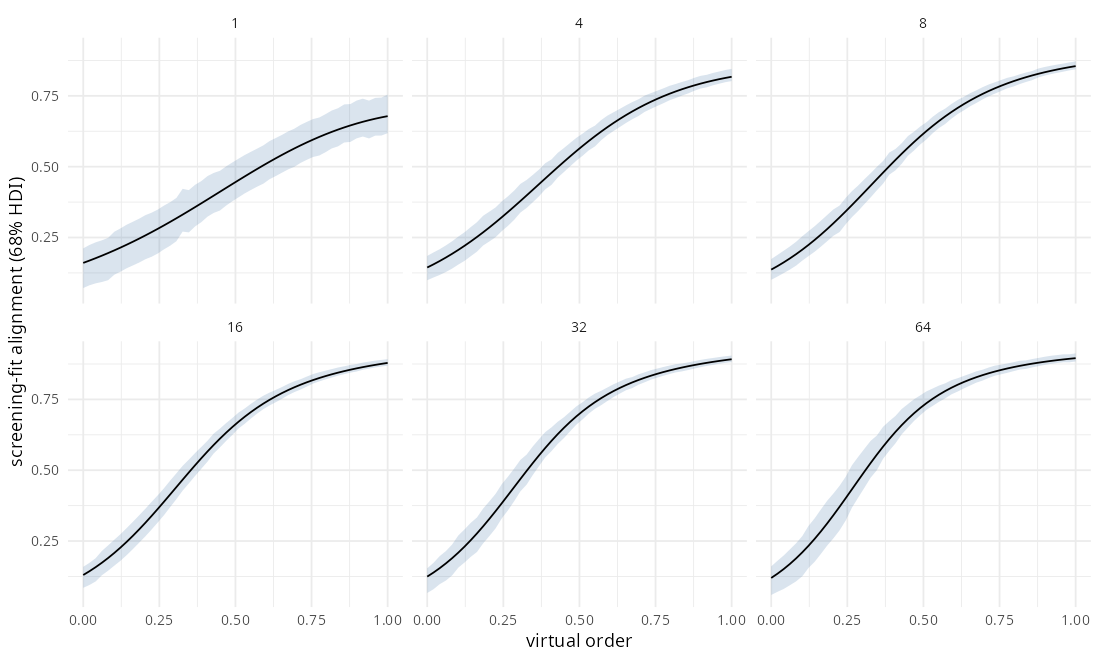

In [10]:
# Initial uncentered screening-fit alignment, 68% HDI as in Python.
screen_grid <- expand.grid(order = seq(0, 1, length.out = 50), density = density_levels)
screen_grid$t_order <- 2 * screen_grid$order - 1
screen_grid$t_density <- 2 * log2(screen_grid$density) / log2(64) - 1
screen_mu <- mod_circular(posterior_linpred(screen_fit, newdata = screen_grid,
                                            dpar = "mu", transform = FALSE))
screen_k <- posterior_linpred(screen_fit, newdata = screen_grid,
                              dpar = "kappa", transform = TRUE)
screen_alignment <- A1_safe(screen_k) * cos(screen_mu)
screen_alignment_df <- do.call(rbind, lapply(seq_len(nrow(screen_grid)), function(j) {
  data.frame(screen_grid[j, c("order", "density")],
    as.list(interval_row(screen_alignment[, j], prob = 0.68)))
}))
p_screen <- ggplot(screen_alignment_df, aes(order, mean)) +
  geom_ribbon(aes(ymin = low, ymax = high), alpha = 0.2, fill = "#4477AA") +
  geom_line() + facet_wrap(~ density) +
  labs(x = "virtual order", y = "screening-fit alignment (68% HDI)")
save_figure(p_screen, "order_density_alignment_screening", 10, 6)


## 3. Individual-level PSIS-LOO model comparison

Fit intercept-only, density, order, additive, and interaction formulas
for **both** mean direction and concentration. Use an
effectively uniform circular mean-intercept prior, Normal `(0, pi/2)` direction
slopes, pre-softplus `Normal(inverse_softplus(2), 1)` concentration
intercept and Normal `(0, 1)` concentration slopes. Preserve default
design-column centering in this sweep. All models use the same animals
in the same order. Pointwise likelihoods and PSIS-LOO are at the animal
level; this is distinct from final-fit step-level LOO.

Evaluate the log densities explicitly from the fitted `mu` and `kappa`
predictors. Pass chain-aware relative efficiencies to `loo`. The comparison reports
ELPD, model-minus-best delta ELPD, its paired SE, and maximum Pareto k.


In [11]:
explicit_loo <- function(fit, newdata, response = "y") {
  draw_index <- posterior::as_draws_df(fit)
  log_lik <- matrix(0, nrow = nrow(draw_index), ncol = nrow(newdata))
  # Keep only the full log-likelihood matrix, evaluating response parameters
  # in observation blocks to limit memory in the 18,641-step final model.
  for (start in seq.int(1L, nrow(newdata), by = 256L)) {
    ii <- seq.int(start, min(start + 255L, nrow(newdata)))
    block <- newdata[ii, , drop = FALSE]
    mu_ll <- mod_circular(posterior_linpred(fit, newdata = block,
                                            dpar = "mu", transform = FALSE))
    k_ll <- posterior_linpred(fit, newdata = block,
                              dpar = "kappa", transform = TRUE)
    log_lik[, ii] <- vm_logpdf(matrix(block[[response]], nrow = nrow(mu_ll),
      ncol = nrow(block), byrow = TRUE), mu_ll, k_ll)
  }
  # Column scaling leaves relative efficiencies unchanged and avoids
  # underflow when converting log likelihoods to likelihoods.
  likelihood <- exp(sweep(log_lik, 2, apply(log_lik, 2, max), "-"))
  r_eff <- loo::relative_eff(likelihood, chain_id = draw_index[[".chain"]])
  loo::loo(log_lik, r_eff = r_eff)
}
candidate_rhs <- c("Intercept-only" = "1", "Density" = "t_density",
  "Order" = "t_order", "Density + Order" = "t_density + t_order",
  "Density x Order" = "t_density * t_order")
# EQUIVALENCE NOTE: the sweep's CircularUniform prior is represented by
# the P0 convention unwrap_von_mises(0, 1e-16), effectively uniform on
# the circle, avoiding a bounded uniform prior on brms's centered intercept.
# Review circular support and the intercept convention in generated Stan.
sweep_fits <- sweep_loo <- vector("list", length(candidate_rhs))
names(sweep_fits) <- names(sweep_loo) <- names(candidate_rhs)
for (name in names(candidate_rhs)) {
  cat("Fitting screening model:", name, "\n")
  rhs <- candidate_rhs[[name]]
  sweep_fits[[name]] <- unwrap_load_fit_cache(paste0("locust_d_screen_", name), SEED, SCREEN_ITER, SCREEN_WARMUP)
  if (is.null(sweep_fits[[name]])) {
    sweep_fits[[name]] <- brm(screen_formula(rhs), data = screen_df,
      prior = screen_priors(rhs, uniform = TRUE),
      stanvars = stan_unwrap_fun + modulo_circular_fun, backend = "cmdstanr",
      chains = CHAINS, iter = SCREEN_ITER, warmup = SCREEN_WARMUP, cores = CHAINS,
      seed = SEED, control = list(adapt_delta = 0.95))
    unwrap_save_fit_cache(paste0("locust_d_screen_", name), sweep_fits[[name]], SEED, SCREEN_ITER, SCREEN_WARMUP)
  }
  print(diagnose_fit(sweep_fits[[name]], "b_Intercept"))
  sweep_loo[[name]] <- explicit_loo(sweep_fits[[name]], screen_df)
}
elpd <- vapply(sweep_loo, function(l) l$estimates["elpd_loo", "Estimate"], numeric(1))
best_name <- names(which.max(elpd))
best_pointwise <- sweep_loo[[best_name]]$pointwise[, "elpd_loo"]
sweep_df <- do.call(rbind, lapply(names(sweep_loo), function(name) {
  l <- sweep_loo[[name]]
  delta <- l$pointwise[, "elpd_loo"] - best_pointwise
  data.frame(model = name, elpd = elpd[[name]],
    delta_elpd = sum(delta), se_delta_elpd = sqrt(length(delta) * var(delta)),
    pareto_k_max = max(l$diagnostics$pareto_k), best_model = best_name)
}))
sweep_df <- sweep_df[order(sweep_df$delta_elpd, decreasing = TRUE), ]
sweep_df


Fitting screening model: Intercept-only 


Start sampling



Running MCMC with 4 parallel chains...

Chain 1 Iteration:    1 / 1500 [  0%]  (Warmup) 
Chain 1 Iteration:  100 / 1500 [  6%]  (Warmup) 
Chain 1 Iteration:  200 / 1500 [ 13%]  (Warmup) 
Chain 1 Iteration:  300 / 1500 [ 20%]  (Warmup) 
Chain 2 Iteration:    1 / 1500 [  0%]  (Warmup) 
Chain 2 Iteration:  100 / 1500 [  6%]  (Warmup) 
Chain 2 Iteration:  200 / 1500 [ 13%]  (Warmup) 
Chain 3 Iteration:    1 / 1500 [  0%]  (Warmup) 
Chain 3 Iteration:  100 / 1500 [  6%]  (Warmup) 
Chain 4 Iteration:    1 / 1500 [  0%]  (Warmup) 
Chain 1 Iteration:  400 / 1500 [ 26%]  (Warmup) 
Chain 2 Iteration:  300 / 1500 [ 20%]  (Warmup) 
Chain 2 Iteration:  400 / 1500 [ 26%]  (Warmup) 
Chain 3 Iteration:  200 / 1500 [ 13%]  (Warmup) 
Chain 4 Iteration:  100 / 1500 [  6%]  (Warmup) 
Chain 1 Iteration:  500 / 1500 [ 33%]  (Warmup) 
Chain 3 Iteration:  300 / 1500 [ 20%]  (Warmup) 
Chain 4 Iteration:  200 / 1500 [ 13%]  (Warmup) 
Chain 1 Iteration:  600 / 1500 [ 40%]  (Warmup) 
Chain 2 Iteration:  500 / 150

Start sampling



Running MCMC with 4 parallel chains...

Chain 1 Iteration:    1 / 1500 [  0%]  (Warmup) 
Chain 1 Iteration:  100 / 1500 [  6%]  (Warmup) 
Chain 2 Iteration:    1 / 1500 [  0%]  (Warmup) 
Chain 2 Iteration:  100 / 1500 [  6%]  (Warmup) 
Chain 3 Iteration:    1 / 1500 [  0%]  (Warmup) 
Chain 4 Iteration:    1 / 1500 [  0%]  (Warmup) 
Chain 1 Iteration:  200 / 1500 [ 13%]  (Warmup) 
Chain 3 Iteration:  100 / 1500 [  6%]  (Warmup) 
Chain 1 Iteration:  300 / 1500 [ 20%]  (Warmup) 
Chain 2 Iteration:  200 / 1500 [ 13%]  (Warmup) 
Chain 4 Iteration:  100 / 1500 [  6%]  (Warmup) 
Chain 3 Iteration:  200 / 1500 [ 13%]  (Warmup) 
Chain 1 Iteration:  400 / 1500 [ 26%]  (Warmup) 
Chain 2 Iteration:  300 / 1500 [ 20%]  (Warmup) 
Chain 4 Iteration:  200 / 1500 [ 13%]  (Warmup) 
Chain 1 Iteration:  500 / 1500 [ 33%]  (Warmup) 
Chain 2 Iteration:  400 / 1500 [ 26%]  (Warmup) 
Chain 3 Iteration:  300 / 1500 [ 20%]  (Warmup) 
Chain 4 Iteration:  300 / 1500 [ 20%]  (Warmup) 
Chain 1 Iteration:  600 / 150

Start sampling



... (2 outputs left out)

Running MCMC with 4 parallel chains...

Chain 1 Iteration:    1 / 1500 [  0%]  (Warmup) 
Chain 2 Iteration:    1 / 1500 [  0%]  (Warmup) 
Chain 3 Iteration:    1 / 1500 [  0%]  (Warmup) 
Chain 4 Iteration:    1 / 1500 [  0%]  (Warmup) 
Chain 1 Iteration:  100 / 1500 [  6%]  (Warmup) 
Chain 2 Iteration:  100 / 1500 [  6%]  (Warmup) 
Chain 3 Iteration:  100 / 1500 [  6%]  (Warmup) 
Chain 2 Iteration:  200 / 1500 [ 13%]  (Warmup) 
Chain 1 Iteration:  200 / 1500 [ 13%]  (Warmup) 
Chain 3 Iteration:  200 / 1500 [ 13%]  (Warmup) 
Chain 4 Iteration:  100 / 1500 [  6%]  (Warmup) 
Chain 1 Iteration:  300 / 1500 [ 20%]  (Warmup) 
Chain 2 Iteration:  300 / 1500 [ 20%]  (Warmup) 
Chain 3 Iteration:  300 / 1500 [ 20%]  (Warmup) 
Chain 4 Iteration:  200 / 1500 [ 13%]  (Warmup) 
Chain 1 Iteration:  400 / 1500 [ 26%]  (Warmup) 
Chain 2 Iteration:  400 / 1500 [ 26%]  (Warmup) 
Chain 3 Iteration:  400 / 1500 [ 26%]  (Warmup) 
Chain 1 Iteration:  500 / 1500 [ 33%]  (Warmup) 
Chain 2 Iteration:  500 / 150

Start sampling



Running MCMC with 4 parallel chains...

Chain 1 Iteration:    1 / 1500 [  0%]  (Warmup) 
Chain 2 Iteration:    1 / 1500 [  0%]  (Warmup) 
Chain 3 Iteration:    1 / 1500 [  0%]  (Warmup) 
Chain 4 Iteration:    1 / 1500 [  0%]  (Warmup) 
Chain 1 Iteration:  100 / 1500 [  6%]  (Warmup) 
Chain 2 Iteration:  100 / 1500 [  6%]  (Warmup) 
Chain 3 Iteration:  100 / 1500 [  6%]  (Warmup) 
Chain 1 Iteration:  200 / 1500 [ 13%]  (Warmup) 
Chain 2 Iteration:  200 / 1500 [ 13%]  (Warmup) 
Chain 4 Iteration:  100 / 1500 [  6%]  (Warmup) 
Chain 1 Iteration:  300 / 1500 [ 20%]  (Warmup) 
Chain 3 Iteration:  200 / 1500 [ 13%]  (Warmup) 
Chain 4 Iteration:  200 / 1500 [ 13%]  (Warmup) 
Chain 2 Iteration:  300 / 1500 [ 20%]  (Warmup) 
Chain 1 Iteration:  400 / 1500 [ 26%]  (Warmup) 
Chain 2 Iteration:  400 / 1500 [ 26%]  (Warmup) 
Chain 3 Iteration:  300 / 1500 [ 20%]  (Warmup) 
Chain 4 Iteration:  300 / 1500 [ 20%]  (Warmup) 
Chain 1 Iteration:  500 / 1500 [ 33%]  (Warmup) 
Chain 2 Iteration:  500 / 150

,model,elpd,delta_elpd,se_delta_elpd,pareto_k_max,best_model
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
5,Density x Order,-590.6468,0.000000,0.000000,0.24934763,Density x Order
4,Density + Order,-592.9556,-2.308822,2.616398,0.23133172,Density x Order
3,Order,-599.7276,-9.080793,5.773973,0.24308804,Density x Order
2,Density,-666.3634,-75.716663,11.583259,0.18644640,Density x Order
1,Intercept-only,-669.2565,-78.609764,11.649550,0.05431795,Density x Order


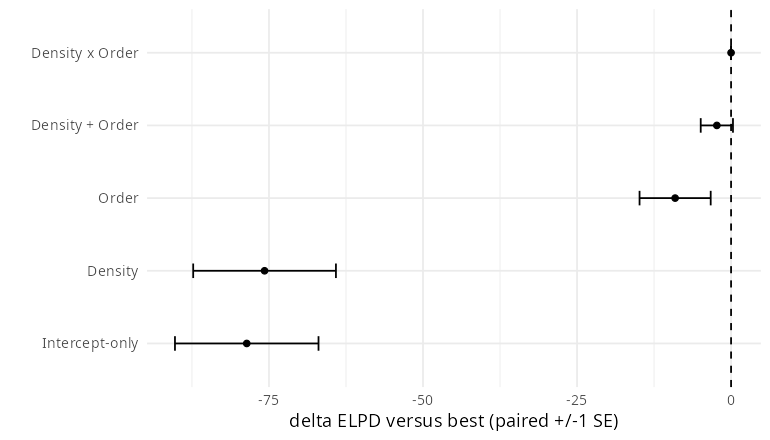

In [12]:
p_selection <- ggplot(sweep_df, aes(delta_elpd, reorder(model, delta_elpd))) +
  geom_errorbar(aes(xmin = delta_elpd - se_delta_elpd,
                    xmax = delta_elpd + se_delta_elpd), orientation = "y", width = 0.2) +
  geom_point() + geom_vline(xintercept = 0, linetype = "dashed") +
  labs(x = "delta ELPD versus best (paired +/-1 SE)", y = "")
save_figure(p_selection, "order_density_model_selection", 7, 4)


## 4. Final step-level hierarchical model

The final model is `y ~ t_density * t_order` with
`kappa ~ t_density * t_order + (1 | animal_id)`. Mean direction has no
random effects: each animal experiences one condition, and the
per-animal direction hierarchy proved weakly identified on this design.
Use all steps.

The direction intercept has `VonMises(0, 3)`, direction main effects
`Normal(0, pi/2)` and interaction `Normal(0, pi/4)`. Pre-softplus
concentration intercept: `Normal(inverse_softplus(2), 0.5)`; main effects
`Normal(0, 0.6)` and interaction `Normal(0, 0.4)`. The individual
concentration intercept is Normal with a positive scale having the
Python Normal `(inverse_softplus(1), 0.3)` density. Default internal
predictor centering is retained, including the interaction design column;
do not manually center the two predictors before taking their product.


In [13]:
data <- merged_df
data$y <- mod_circular(data$direction)
data$t_order <- 2 * data$order - 1
data$t_density <- 2 * log2(data$density) / log2(64) - 1
form_vonmises <- bf(y ~ t_density * t_order,
  kappa ~ t_density * t_order + (1 | animal_id), family = unwrap_von_mises)
prior_vonmises <- (
  prior("unwrap_von_mises(0, 3)", class = "Intercept") +
  prior("normal(0, pi()/2)", class = "b", coef = "t_density") +
  prior("normal(0, pi()/2)", class = "b", coef = "t_order") +
  prior("normal(0, pi()/4)", class = "b", coef = "t_density:t_order") +
  prior("normal(log(exp(2) - 1), 0.5)", class = "Intercept", dpar = "kappa") +
  prior("normal(0, 0.6)", class = "b", coef = "t_density", dpar = "kappa") +
  prior("normal(0, 0.6)", class = "b", coef = "t_order", dpar = "kappa") +
  prior("normal(0, 0.4)", class = "b", coef = "t_density:t_order", dpar = "kappa") +
  prior("normal(log(exp(1) - 1), 0.3)", class = "sd", dpar = "kappa")
)
# EQUIVALENCE NOTE: PyMC's Normal(..., transform=LogExpM1()) for sigma
# changes its positive-support coordinate, not the Normal density into a
# softplus-normal generative prior. brms's positive sd with the same Normal
# density matches that constrained target (a truncated Normal), rather than
# softplus(Normal(...)). Confirm this interpretation against the Python fit.
# EQUIVALENCE NOTE: brms and Bambi internally center design columns while
# returning ordinary-scale intercept draws. posterior_linpred handles that
# conversion. Do not reuse the Python posthoc helper's manually centered
# interaction grid here; check fitted predictions against the PyMC graph.
prior_vonmises


prior,class,coef,group,resp,dpar,nlpar,lb,ub,tag,source
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>
"unwrap_von_mises(0, 3)",Intercept,,,,,,NA,NA,,user
"normal(0, pi()/2)",b,t_density,,,,,NA,NA,,user
"normal(0, pi()/2)",b,t_order,,,,,NA,NA,,user
"normal(0, pi()/4)",b,t_density:t_order,,,,,NA,NA,,user
"normal(log(exp(2) - 1), 0.5)",Intercept,,,,kappa,,NA,NA,,user
"normal(0, 0.6)",b,t_density,,,kappa,,NA,NA,,user
"normal(0, 0.6)",b,t_order,,,kappa,,NA,NA,,user
"normal(0, 0.4)",b,t_density:t_order,,,kappa,,NA,NA,,user
"normal(log(exp(1) - 1), 0.3)",sd,,,,kappa,,NA,NA,,user


In [14]:
fit <- unwrap_load_fit_cache("locust_d_final", SEED, ITER, WARMUP)
if (is.null(fit)) {
  fit <- brm(form_vonmises, data = data, prior = prior_vonmises,
    stanvars = stan_unwrap_fun + modulo_circular_fun, backend = "cmdstanr",
    chains = CHAINS, iter = ITER, warmup = WARMUP, cores = CHAINS,
    seed = SEED, control = list(adapt_delta = ADAPT_DELTA))
  unwrap_save_fit_cache("locust_d_final", fit, SEED, ITER, WARMUP)
}


Start sampling



Running MCMC with 4 parallel chains...

Chain 1 Iteration:    1 / 2250 [  0%]  (Warmup) 
Chain 2 Iteration:    1 / 2250 [  0%]  (Warmup) 
Chain 3 Iteration:    1 / 2250 [  0%]  (Warmup) 
Chain 4 Iteration:    1 / 2250 [  0%]  (Warmup) 
Chain 3 Iteration:  100 / 2250 [  4%]  (Warmup) 
Chain 4 Iteration:  100 / 2250 [  4%]  (Warmup) 
Chain 1 Iteration:  100 / 2250 [  4%]  (Warmup) 
Chain 3 Iteration:  200 / 2250 [  8%]  (Warmup) 
Chain 4 Iteration:  200 / 2250 [  8%]  (Warmup) 
Chain 3 Iteration:  300 / 2250 [ 13%]  (Warmup) 
Chain 2 Iteration:  100 / 2250 [  4%]  (Warmup) 
Chain 4 Iteration:  300 / 2250 [ 13%]  (Warmup) 
Chain 3 Iteration:  400 / 2250 [ 17%]  (Warmup) 
Chain 1 Iteration:  200 / 2250 [  8%]  (Warmup) 
Chain 4 Iteration:  400 / 2250 [ 17%]  (Warmup) 
Chain 3 Iteration:  500 / 2250 [ 22%]  (Warmup) 
Chain 3 Iteration:  600 / 2250 [ 26%]  (Warmup) 
Chain 2 Iteration:  200 / 2250 [  8%]  (Warmup) 
Chain 4 Iteration:  500 / 2250 [ 22%]  (Warmup) 
Chain 1 Iteration:  300 / 225

## Diagnostics and traces

Inspect the divergence probe, circular-intercept R-hat, ordinary R-hat
for the remaining coefficients and group effects, and bulk ESS. The
summary includes the individual concentration effects and their scale.


In [15]:
circular_parameters <- "b_Intercept"
summary_frame <- diagnose_fit(fit, circular_parameters)
summary_frame


Divergences: not retained in this fit object (see R-hat/ESS below).


parameter,mean,sd,rhat,ess_bulk
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
b_Intercept,-0.06608227,0.01369096,1.0014,1717.7
b_kappa_Intercept,0.43528174,0.11366786,1.0034,275.7
b_t_density,-0.14454307,0.01908206,1.0000,1907.4
b_t_order,0.07178752,0.01782011,1.0008,1645.3
b_t_density:t_order,0.15765292,0.02605382,0.9998,1943.9
b_kappa_t_density,0.41562968,0.16530581,1.0004,370.6
b_kappa_t_order,2.33365282,0.15796213,1.0007,473.3
b_kappa_t_density:t_order,0.64951775,0.21309060,1.0016,640.7
sd_animal_id__kappa_Intercept,1.92238978,0.08842892,0.9997,882.5


In [16]:
summary_frame[!is.finite(summary_frame$rhat) | summary_frame$rhat >= 1.01 |
              !is.finite(summary_frame$ess_bulk) | summary_frame$ess_bulk <= 400, ]


,parameter,mean,sd,rhat,ess_bulk
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
2,b_kappa_Intercept,0.4352817,0.1136679,1.0034,275.7
6,b_kappa_t_density,0.4156297,0.1653058,1.0004,370.6


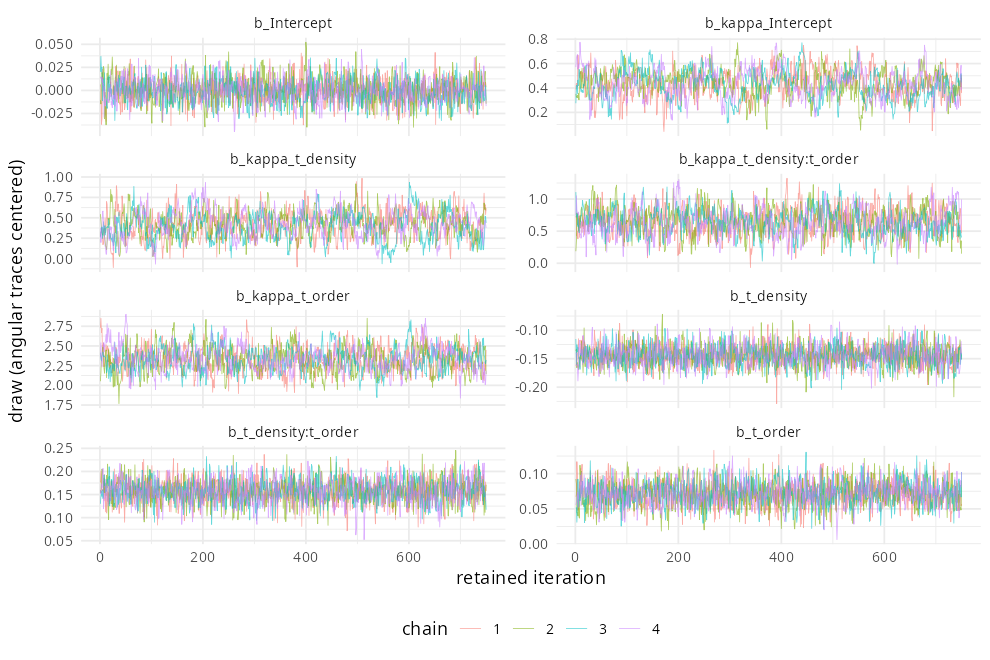

In [17]:
trace_parameters <- c("b_Intercept", "b_t_density", "b_t_order", "b_t_density:t_order",
  "b_kappa_Intercept", "b_kappa_t_density", "b_kappa_t_order", "b_kappa_t_density:t_order")

# as_draws_df is wide: explicitly assemble a long trace table.
draws_df <- posterior::as_draws_df(posterior::subset_draws(
    posterior::as_draws_array(fit), variable = trace_parameters))
trace_df <- do.call(rbind, lapply(trace_parameters, function(p) {
  value <- as.numeric(draws_df[[p]])
  if (p %in% circular_parameters) value <- mod_circular(value - circ_mean(value))
  data.frame(parameter = p, value = value,
             iteration = draws_df[[".iteration"]],
             chain = factor(draws_df[[".chain"]]))
}))
p_trace <- ggplot(trace_df, aes(iteration, value, colour = chain)) +
  geom_line(alpha = 0.6, linewidth = 0.25) +
  facet_wrap(~ parameter, scales = "free_y", ncol = 2) +
  labs(x = "retained iteration", y = "draw (angular traces centered)") +
  theme(legend.position = "bottom")
save_figure(p_trace, "trace", 9, 6)


In [18]:
# Step-level conditional LOO, as in the Python final-fit notebook.
# This is not leave-one-animal-out validation and is not compared against
# the individual-level screening ELPDs.
final_loo <- explicit_loo(fit, data)
final_loo
c(p_loo = final_loo$estimates["p_loo", "Estimate"],
  N_over_p_loo = nrow(data) / final_loo$estimates["p_loo", "Estimate"],
  fraction_pareto_k_above_0.7 = mean(final_loo$diagnostics$pareto_k > 0.7))


Warning message:
“Some Pareto k diagnostic values are too high. See help('pareto-k-diagnostic') for details.
”



Computed from 3000 posterior draws and 18641 log-likelihood terms.

         Estimate    SE
elpd_loo -26224.0 103.1
p_loo       280.7   6.6
looic     52448.0 206.3
------
MCSE of elpd_loo is NA.
MCSE and ESS estimates assume MCMC draws (r_eff in [0.3, 2.1]).

Pareto k diagnostic values:
                         Count Pct.    Min. ESS
(-Inf, 0.7]   (good)     18607 99.8%   181     
   (0.7, 1]   (bad)         11  0.1%   <NA>    
   (1, Inf)   (very bad)    23  0.1%   <NA>    
See help('pareto-k-diagnostic') for details.

p_loo                N_over_p_loo 
               2.807212e+02                6.640395e+01 
fraction_pareto_k_above_0.7 
               1.823936e-03

## 5. Predictions: alignment, density at zero, and directional PDFs

Evaluate `mu` and positive `kappa` with the fitted brms predictors.
Population curves exclude individual deviations, so they describe an
animal with zero concentration deviation, as in the Python fixed-effect
prediction surfaces. These curves are not marginal averages over new
individuals. Predictive density at zero is a density per radian, distinct
from probability mass in an angular sector.


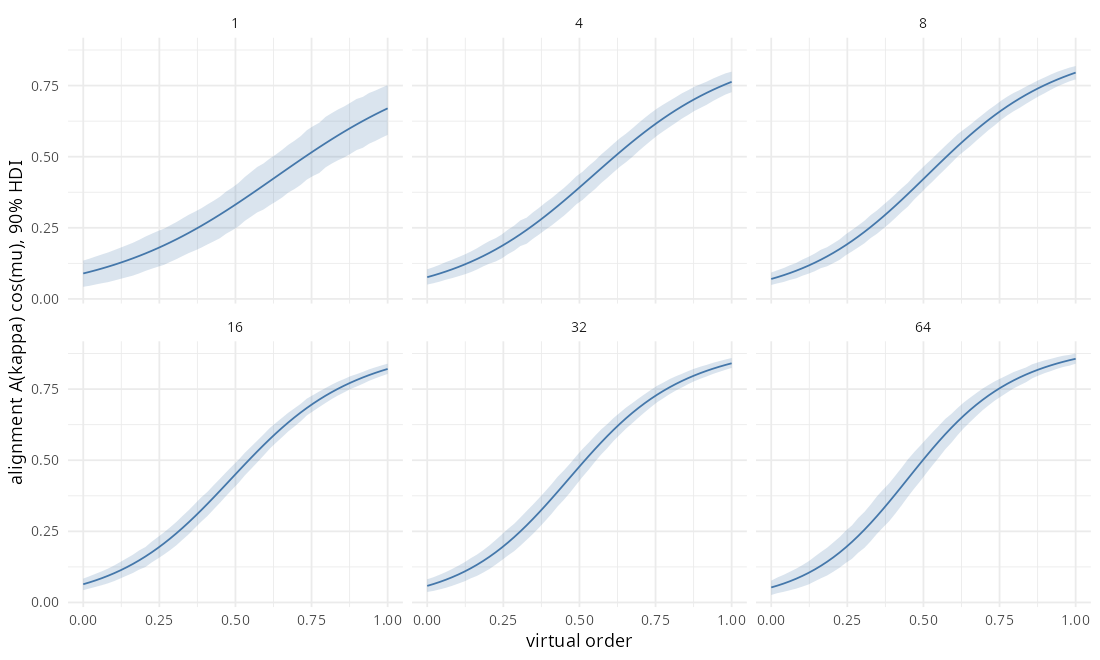

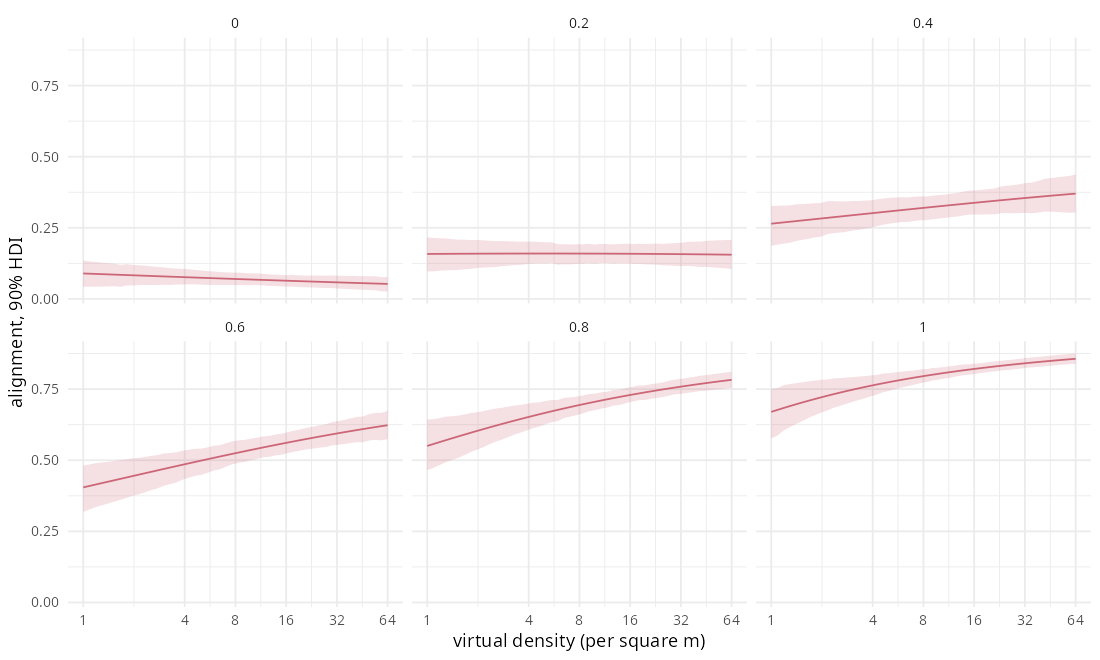

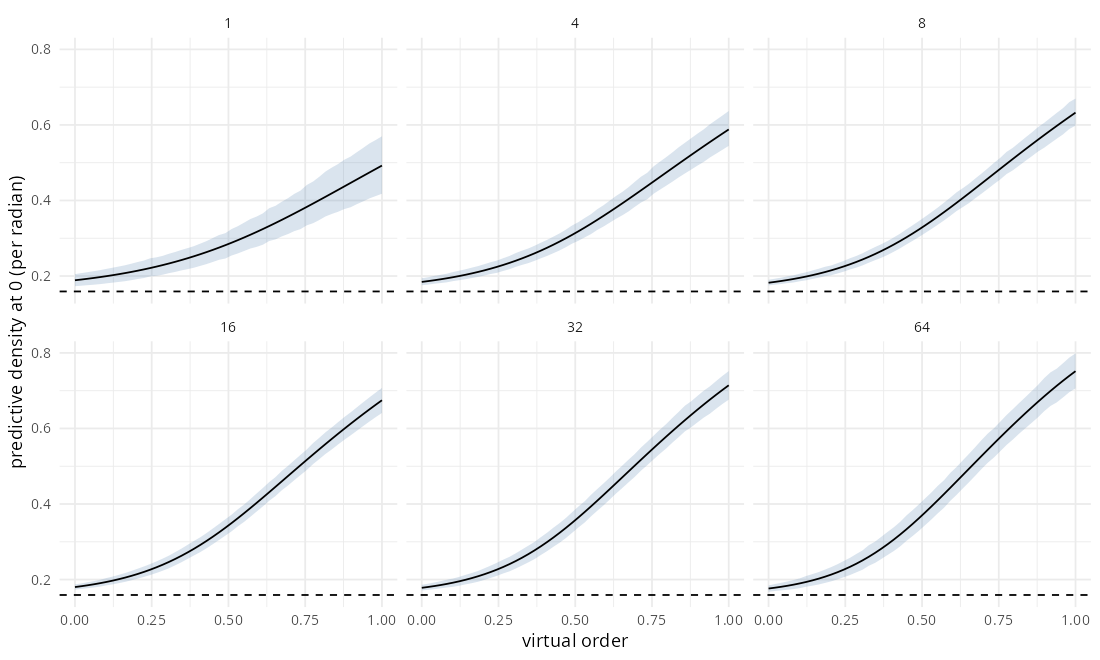

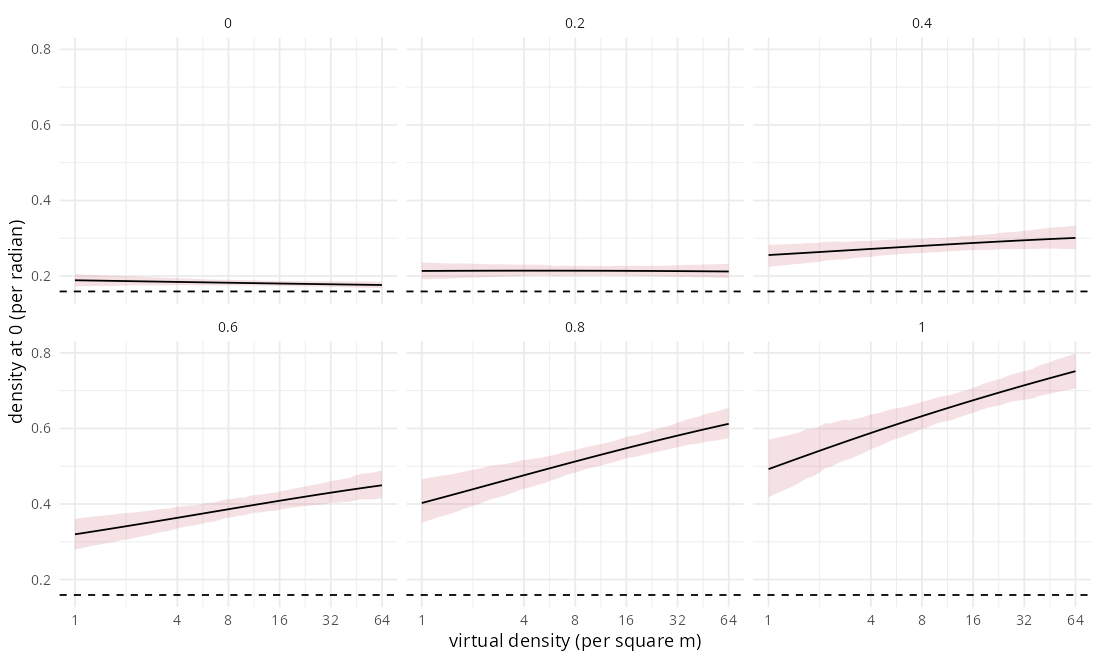

In [19]:
grid <- expand.grid(order = seq(0, 1, length.out = 50), density = density_levels)
grid$t_order <- 2 * grid$order - 1
grid$t_density <- 2 * log2(grid$density) / log2(64) - 1
grid$animal_id <- data$animal_id[1]
mu_grid <- mod_circular(posterior_linpred(fit, newdata = grid,
  dpar = "mu", transform = FALSE, re_formula = NA))
k_grid <- posterior_linpred(fit, newdata = grid,
  dpar = "kappa", transform = TRUE, re_formula = NA)
alignment <- A1_safe(k_grid) * cos(mu_grid)
alignment_summary <- do.call(rbind, lapply(seq_len(nrow(grid)), function(j) {
  data.frame(grid[j, c("order", "density")], as.list(interval_row(alignment[, j], prob = 0.9)))
}))
p_alignment <- ggplot(alignment_summary, aes(order, mean)) +
  geom_ribbon(aes(ymin = low, ymax = high), fill = "#4477AA", alpha = 0.2) +
  geom_line(colour = "#4477AA") + facet_wrap(~ density) +
  labs(x = "virtual order", y = "alignment A(kappa) cos(mu), 90% HDI")
save_figure(p_alignment, "order_density_alignment", 10, 6)

density_grid <- expand.grid(density = 2^seq(0, 6, length.out = 50), order = order_levels)
density_grid$t_order <- 2 * density_grid$order - 1
density_grid$t_density <- 2 * log2(density_grid$density) / log2(64) - 1
density_grid$animal_id <- data$animal_id[1]
mu_density <- mod_circular(posterior_linpred(fit, newdata = density_grid,
  dpar = "mu", transform = FALSE, re_formula = NA))
k_density <- posterior_linpred(fit, newdata = density_grid,
  dpar = "kappa", transform = TRUE, re_formula = NA)
density_summary <- do.call(rbind, lapply(seq_len(nrow(density_grid)), function(j) {
  data.frame(density_grid[j, c("order", "density")],
    as.list(interval_row(A1_safe(k_density[, j]) * cos(mu_density[, j]), prob = 0.9)))
}))
p_density_alignment <- ggplot(density_summary, aes(density, mean)) +
  geom_ribbon(aes(ymin = low, ymax = high), fill = "#CC6677", alpha = 0.2) +
  geom_line(colour = "#CC6677") + scale_x_continuous(trans = "log2", breaks = density_levels) +
  facet_wrap(~ order) + labs(x = "virtual density (per square m)", y = "alignment, 90% HDI")
save_figure(p_density_alignment, "density_order_alignment", 10, 6)

summarize_log_density <- function(m, k, newdata) {
  do.call(rbind, lapply(seq_len(nrow(newdata)), function(j) {
    lp <- vm_logpdf(0, m[, j], k[, j])
    # Python summarizes in log space, then exponentiates the interval.
    s <- interval_row(lp, prob = 0.9)
    data.frame(newdata[j, c("order", "density")], as.list(exp(s)))
  }))
}
pdf0 <- summarize_log_density(mu_grid, k_grid, grid)
p_pdf0 <- ggplot(pdf0, aes(order, mean)) +
  geom_ribbon(aes(ymin = low, ymax = high), alpha = 0.2, fill = "#4477AA") +
  geom_line() + geom_hline(yintercept = 1 / (2 * pi), linetype = "dashed") +
  facet_wrap(~ density) + labs(x = "virtual order", y = "predictive density at 0 (per radian)")
save_figure(p_pdf0, "order_density_elpd0", 10, 6)
pdf0_density <- summarize_log_density(mu_density, k_density, density_grid)
p_pdf0_density <- ggplot(pdf0_density, aes(density, mean)) +
  geom_ribbon(aes(ymin = low, ymax = high), alpha = 0.2, fill = "#CC6677") +
  geom_line() + geom_hline(yintercept = 1 / (2 * pi), linetype = "dashed") +
  scale_x_continuous(trans = "log2", breaks = density_levels) +
  facet_wrap(~ order) + labs(x = "virtual density (per square m)", y = "density at 0 (per radian)")
save_figure(p_pdf0_density, "density_order_elpd0", 10, 6)


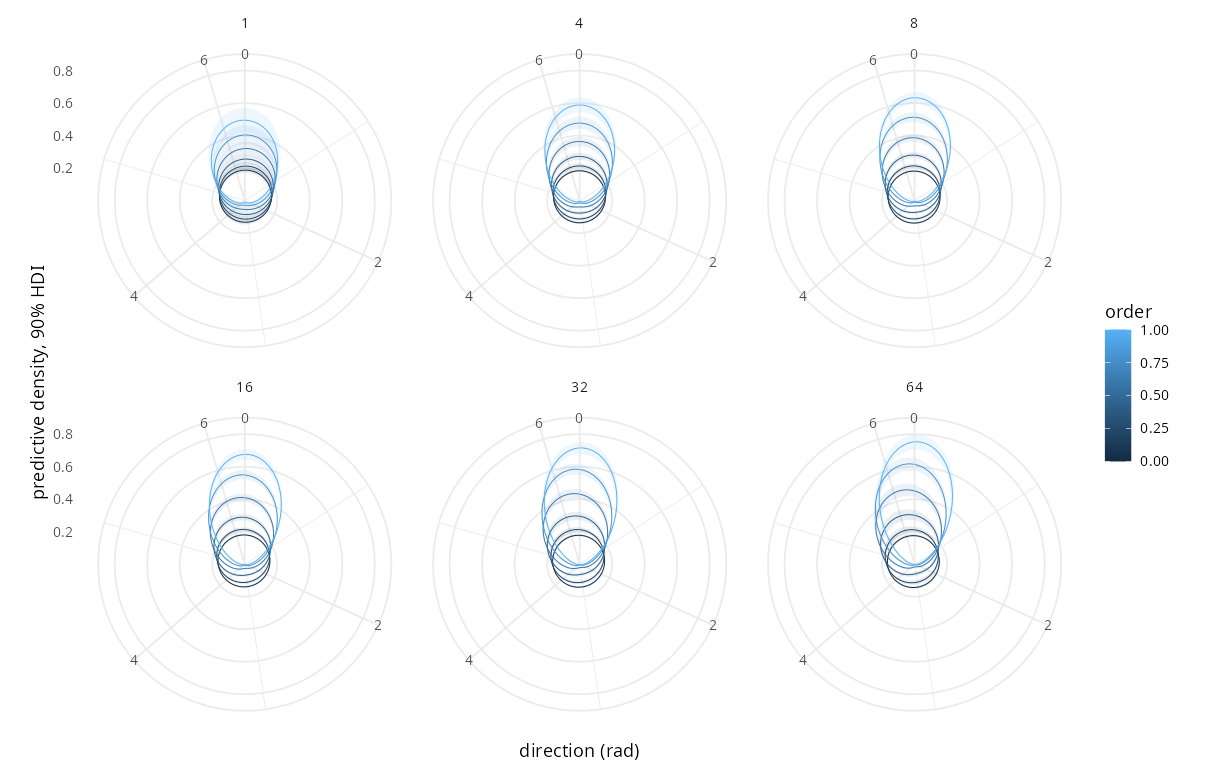

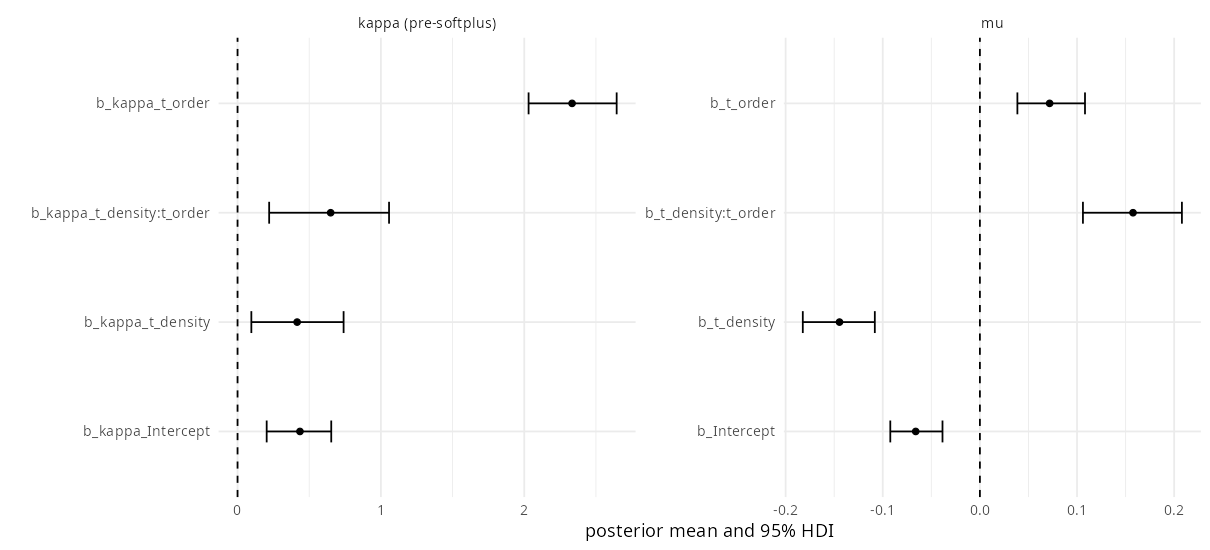

In [20]:
cell_grid <- expand.grid(order = order_levels, density = density_levels)
cell_grid$t_order <- 2 * cell_grid$order - 1
cell_grid$t_density <- 2 * log2(cell_grid$density) / log2(64) - 1
cell_grid$animal_id <- data$animal_id[1]
m_cell <- mod_circular(posterior_linpred(fit, newdata = cell_grid,
  dpar = "mu", transform = FALSE, re_formula = NA))
k_cell <- posterior_linpred(fit, newdata = cell_grid,
  dpar = "kappa", transform = TRUE, re_formula = NA)
theta <- seq(-pi, pi, length.out = 900)
pdf_summary <- do.call(rbind, lapply(seq_len(nrow(cell_grid)), function(j) {
  do.call(rbind, lapply(theta, function(t) {
    p <- exp(vm_logpdf(t, m_cell[, j], k_cell[, j]))
    data.frame(order = cell_grid$order[j], density = cell_grid$density[j],
      theta = t %% (2 * pi), median = median(p), as.list(hdi(p, 0.9)))
  }))
}))
p_polar <- ggplot(pdf_summary, aes(theta, median, colour = order, group = order)) +
  geom_ribbon(aes(ymin = low, ymax = high, fill = order), alpha = 0.1, colour = NA) +
  geom_line(linewidth = 0.3) + facet_wrap(~ density) + coord_polar() +
  scale_x_continuous(limits = c(0, 2 * pi), expand = c(0, 0)) +
  labs(x = "direction (rad)", y = "predictive density, 90% HDI")
save_figure(p_polar, "order_density_polar_pdfs_grid", 11, 7)

coefficient_draws <- as.data.frame(posterior::as_draws_df(fit))
coefficient_summary <- do.call(rbind, lapply(trace_parameters, function(p) {
  data.frame(parameter = p, component = if (grepl("b_kappa_", p)) "kappa (pre-softplus)" else "mu",
    as.list(interval_row(coefficient_draws[[p]], angular = p == "b_Intercept")))
}))
p_coefficients <- ggplot(coefficient_summary, aes(mean, parameter)) +
  geom_errorbar(aes(xmin = low, xmax = high), orientation = "y", width = 0.2) +
  geom_point() + geom_vline(xintercept = 0, linetype = "dashed") +
  facet_wrap(~ component, scales = "free") + labs(x = "posterior mean and 95% HDI", y = "")
save_figure(p_coefficients, "order_density_coefficients", 11, 5)


## 6. Cell-level and individual posterior predictive checks

Match the Python statistic $\overline{\cos\theta}$: alignment at zero.
Within each observed order-density cell, the empirical hierarchical
bootstrap resamples animals, then steps within animals, weighting
animals equally. Conditional predictive replicates use each animal's
fitted concentration effect and the original number of steps. Apply the
same bootstrap to replicated datasets. Individual panels compare a
within-animal step bootstrap with predictive replicates. Plot 95% HDIs.


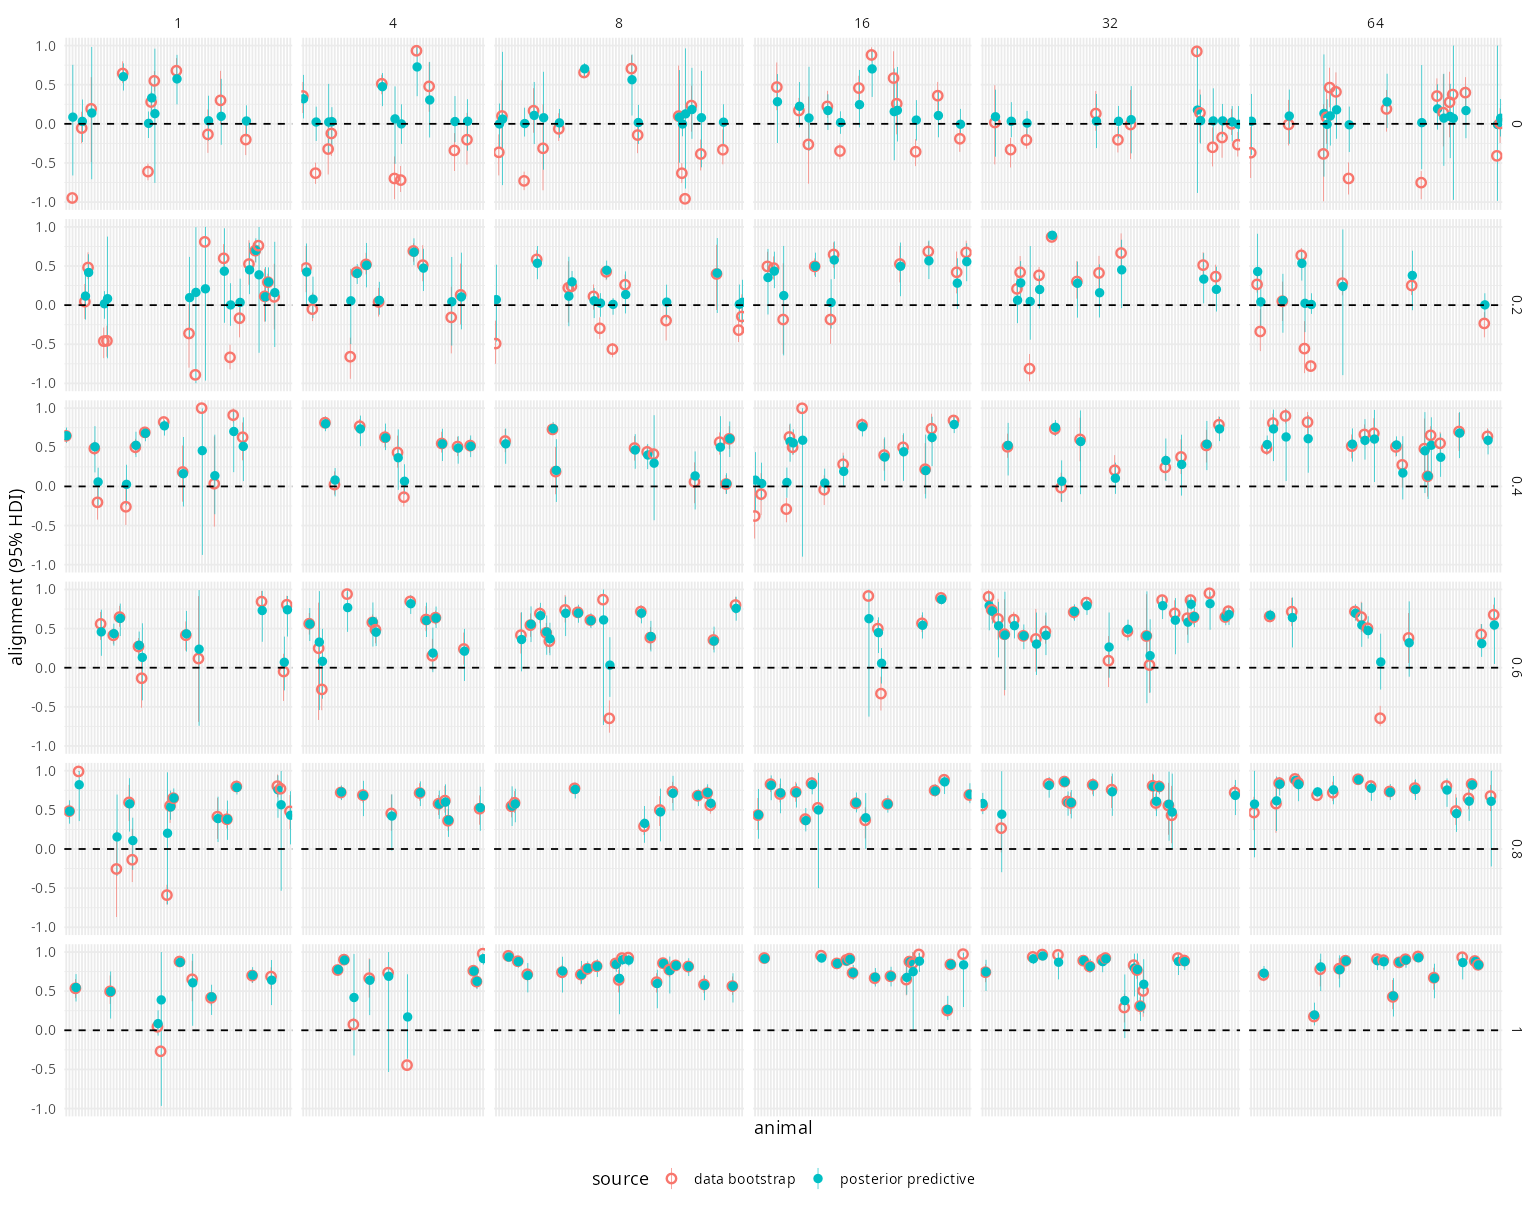

In [21]:
set.seed(SEED + 30L)
B_DATA <- if (quick_run) 150L else 1000L
B_MODEL <- if (quick_run) 100L else 600L
B_INDIV <- if (quick_run) 150L else 800L
N_REPLICATES <- if (quick_run) 100L else 400L
draw_ids <- sample.int(posterior::ndraws(posterior::as_draws_array(fit)), N_REPLICATES)
# Subset before allocating draw x observation matrices (~18,641 columns).
mu_obs <- mod_circular(posterior_linpred(fit, dpar = "mu", transform = FALSE, draw_ids = draw_ids))
k_obs <- posterior_linpred(fit, dpar = "kappa", transform = TRUE, draw_ids = draw_ids)
yrep <- simulate_angles(mu_obs, k_obs)
animal_rows <- split(seq_len(nrow(data)), data$animal_id)
animal_metadata <- data[vapply(animal_rows, function(ii) ii[1], integer(1)),
                        c("animal_id", "order", "density")]
individual_ppc <- do.call(rbind, lapply(seq_along(animal_rows), function(j) {
  ii <- animal_rows[[j]]
  y <- data$y[ii]
  empirical <- replicate(B_INDIV, mean(cos(y[sample.int(length(y), length(y), replace = TRUE)])))
  predictive <- rowMeans(cos(yrep[, ii, drop = FALSE]))
  rbind(data.frame(animal_metadata[j, ], source = "data bootstrap",
    as.list(interval_row(empirical))),
    data.frame(animal_metadata[j, ], source = "posterior predictive",
    as.list(interval_row(predictive))))
}))
p_individual_ppc <- ggplot(individual_ppc,
  aes(animal_id, mean, colour = source, shape = source)) +
  geom_pointrange(aes(ymin = low, ymax = high), position = position_dodge(width = 0.4),
                  linewidth = 0.2) +
  geom_hline(yintercept = 0, linetype = "dashed") +
  facet_grid(order ~ density, scales = "free_x", space = "free_x") +
  scale_shape_manual(values = c("data bootstrap" = 1, "posterior predictive" = 16)) +
  labs(x = "animal", y = "alignment (95% HDI)") +
  theme(axis.text.x = element_blank(), axis.ticks.x = element_blank(),
        legend.position = "bottom")
save_figure(p_individual_ppc, "order_density_individual_cell_ppc", 14, 11)


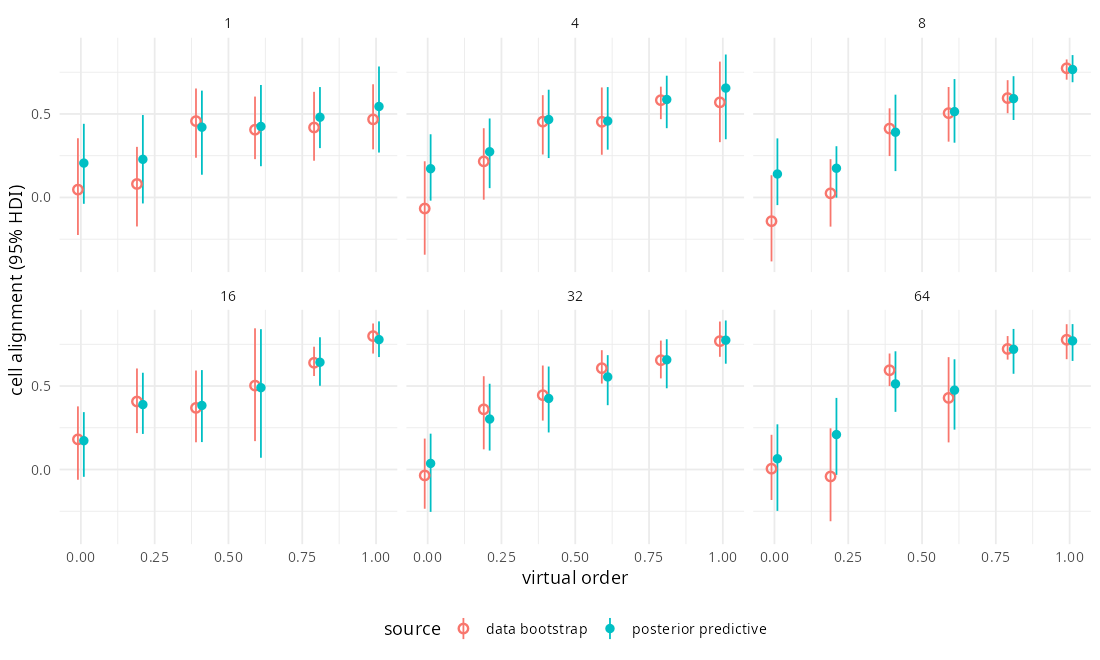

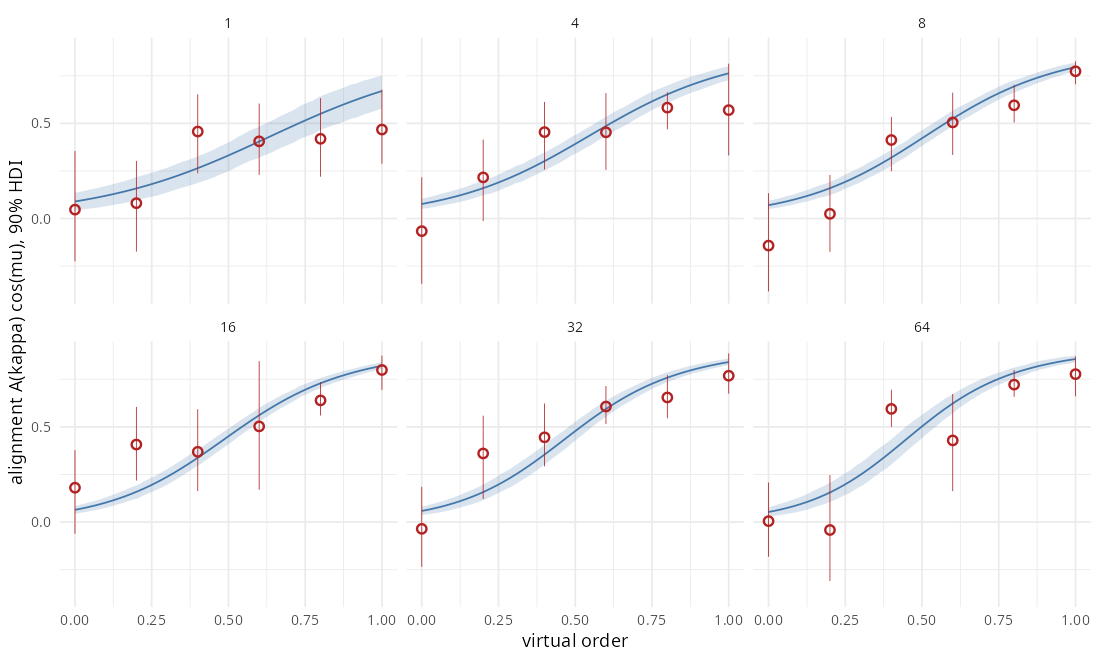

In [22]:
cell_rows <- split(seq_len(nrow(animal_metadata)),
  interaction(animal_metadata$order, animal_metadata$density, drop = TRUE))
cell_ppc <- do.call(rbind, lapply(cell_rows, function(animals) {
  empirical <- replicate(B_DATA, {
    selected <- animals[sample.int(length(animals), length(animals), replace = TRUE)]
    mean(vapply(selected, function(j) {
      y <- data$y[animal_rows[[j]]]
      mean(cos(y[sample.int(length(y), length(y), replace = TRUE)]))
    }, numeric(1)))
  })
  predictive <- replicate(B_MODEL, {
    d <- sample.int(nrow(yrep), 1)
    selected <- animals[sample.int(length(animals), length(animals), replace = TRUE)]
    mean(vapply(selected, function(j) {
      y <- yrep[d, animal_rows[[j]]]
      mean(cos(y[sample.int(length(y), length(y), replace = TRUE)]))
    }, numeric(1)))
  })
  g <- animal_metadata[animals[1], c("order", "density")]
  rbind(data.frame(g, source = "data bootstrap", as.list(interval_row(empirical))),
    data.frame(g, source = "posterior predictive", as.list(interval_row(predictive))))
}))
p_cell_ppc <- ggplot(cell_ppc, aes(order, mean, colour = source, shape = source)) +
  geom_pointrange(aes(ymin = low, ymax = high), position = position_dodge(width = 0.04)) +
  facet_wrap(~ density) +
  scale_shape_manual(values = c("data bootstrap" = 1, "posterior predictive" = 16)) +
  labs(x = "virtual order", y = "cell alignment (95% HDI)") + theme(legend.position = "bottom")
save_figure(p_cell_ppc, "order_density_cell_ppc_dots", 10, 6)
p_alignment_boot <- p_alignment +
  geom_pointrange(data = cell_ppc[cell_ppc$source == "data bootstrap", ],
    aes(x = order, y = mean, ymin = low, ymax = high), inherit.aes = FALSE,
    shape = 1, colour = "firebrick", linewidth = 0.25)
save_figure(p_alignment_boot, "order_density_alignment_ppc_bootstrap", 10, 6)


## Limitations

Review Pareto k before trusting PSIS-LOO differences; use refitting
or a more appropriate validation design if influential animals make
the approximation unreliable. Step-level conditional LOO does not
measure performance on new animals. The fitted interaction is the
final specification for this analysis.

See the [model guide](../models.md), [circular GLMM guide](../math/glmms.md),
and [R setup](../getting-started-r.md) for the statistical framework and
environment.